# 03 Восстановление дюрации и выпуклости

Обучим отдельный CatBoost для каждой метрики. Сравним модели с простыми медианными
оценками, проверим качество по времени и на новых эмитентах. Затем оценим интервалы
неопределённости и ошибку риска предполагаемой сделки.

Модель использует характеристики облигации на дату оценки. Режим без текущей
доходности проверяется отдельно. Это восстановление недостающих метрик,
а не прогноз цены и не рекомендация совершить сделку.

Выводы написаны в Markdown по сохранённым результатам. При обновлении данных
их нужно пересмотреть.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA = Path("notebooks/price_imputation/data") if Path("notebooks/price_imputation").exists() else Path("data")
MODELS = DATA / "models"
MODELS.mkdir(exist_ok=True)
SEED = 42
THREADS = 4
ITERATIONS = 500
market_hash_before = hashlib.sha256((DATA / "market_data.parquet").read_bytes()).hexdigest()
all_data = pd.read_parquet(DATA / "model_dataset.parquet")
TARGETS = ["duration_mod", "convexity"]
print("Источник: MOEX ISS; период", all_data["trade_date"].min().date(), "-", all_data["trade_date"].max().date())
print("Все строки:", len(all_data), "дубликаты:", int(all_data.duplicated(["SECID", "trade_date"]).sum()))
display(all_data[TARGETS].agg(["count", "min", "median", "max"]))

gold = all_data[all_data["ml_eligible"]].dropna(subset=TARGETS).copy()
gold = gold[np.isfinite(gold[TARGETS]).all(axis=1) & gold[TARGETS].ge(0).all(axis=1)]
gold = gold.sort_values(["trade_date", "SECID"]).reset_index(drop=True)
assert gold["coupon_type"].isin(["fixed", "zero"]).all()
assert gold["settlement_calendar_exact"].all()
print("Gold:", len(gold), "выпусков:", gold["SECID"].nunique(), "эмитентов:", gold["issuer_id"].nunique())

Источник: MOEX ISS; период 2022-01-03 - 2026-10-23
Все строки: 917912 дубликаты: 0


,duration_mod,convexity
count,838854.000000,774263.000000
min,0.000249,0.000000
median,0.944493,1.656793
max,30.896921,561.009453


Gold: 392902 выпусков: 1024 эмитентов: 310


## Признаки и проверка утечки

Срок до погашения и до исторической даты расчёта доходности, известная ставка купона,
частота по прошедшему периоду, валюта, номинал и текущая доходность.
Сектора и рейтинга в истории нет. Уровень листинга не используем вместо рейтинга.

Доходность может отсутствовать. Поэтому случайно скрываем её у 20% обучающих строк
и отдельно оцениваем режим полностью без доходности. Ответы не скрываем в обучении;
в проверке модель получает только X, а ответы используются лишь для подсчёта ошибки.

Текущие справочник и графики ограничивают выборку: есть смещение к сохранившимся выпускам.
Фильтр качества целей построен по сверке расчётов. Это исследование на отобранной выборке,
а не доказательство качества для всех выпусков и любых причин пропуска.

In [2]:
FEATURES = ["years_to_maturity", "years_to_yield_date", "coupon_type_asof", "coupon_freq_asof",
            "coupon_period_days_asof", "coupon_percent", "coupon_value", "currency_asof",
            "face_value", "ytm", "has_buyback", "is_government"]
CATEGORICAL = ["coupon_type_asof", "currency_asof"]
assert not set(FEATURES) & {"duration_mod", "convexity", "DURATION", "duration_calc", "SECID", "isin", "issuer_id"}

def make_x(frame, without_yield=False):
    x = frame[FEATURES].copy()
    for col in CATEGORICAL:
        x[col] = x[col].fillna("unknown_at_date").astype(str)
    for col in set(FEATURES) - set(CATEGORICAL):
        x[col] = pd.to_numeric(x[col], errors="coerce").astype(float).replace([np.inf, -np.inf], np.nan)
    if without_yield:
        x["ytm"] = np.nan
    return x

display(pd.DataFrame({"пропуски, %": gold[FEATURES].isna().mean()*100,
                      "уникальных": gold[FEATURES].nunique()}).round(2))

,"пропуски, %",уникальных
years_to_maturity,1.95,7918
years_to_yield_date,0.00,6971
coupon_type_asof,0.00,4
coupon_freq_asof,5.97,24
coupon_period_days_asof,5.97,75
coupon_percent,0.00,338
coupon_value,0.00,1619
currency_asof,0.00,5
face_value,0.00,725
ytm,0.00,10588


## Разделение по времени и эмитентам

Первые 65% дат - обучение, следующие 10% - выбор числа деревьев,
следующие 10% - калибровка интервалов, последние 15% - окончательная проверка.

Дополнительно заранее выбираем 20% известных корпоративных эмитентов и исключаем
всю их историю из обучения, подбора и калибровки. На последнем периоде отдельно
показываем результаты для этих эмитентов. Названия и идентификаторы не входят в X.
Если эмитент неизвестен, строка не участвует в проверке новых эмитентов.

In [3]:
dates = np.sort(gold["trade_date"].unique())
train_end, valid_end, calibration_end = [pd.Timestamp(dates[int(len(dates)*q)]) for q in [.65, .75, .85]]
issuer_pool = sorted(gold.loc[gold["issuer_id"].notna() & gold["is_government"].eq(0), "issuer_id"].unique())
rng = np.random.default_rng(SEED)
unseen_issuers = set(rng.choice(issuer_pool, size=max(1, int(len(issuer_pool)*.2)), replace=False))
is_unseen = gold["issuer_id"].isin(unseen_issuers)
train = gold[(gold["trade_date"] < train_end) & ~is_unseen].copy()
valid = gold[gold["trade_date"].between(train_end, valid_end, inclusive="left") & ~is_unseen].copy()
calibration = gold[gold["trade_date"].between(valid_end, calibration_end, inclusive="left") & ~is_unseen].copy()
test_seen = gold[(gold["trade_date"] >= calibration_end) & ~is_unseen].copy()
test_unseen = gold[(gold["trade_date"] >= calibration_end) & is_unseen].copy()
splits = {"train": train, "validation": valid, "calibration": calibration,
          "test_time": test_seen, "test_unseen_issuers": test_unseen}
display(pd.DataFrame([{ "выборка": name, "строк": len(frame), "выпусков": frame["SECID"].nunique(),
                       "эмитентов": frame["issuer_id"].nunique(), "начало": frame["trade_date"].min(),
                       "конец": frame["trade_date"].max()} for name, frame in splits.items()]))
assert train["trade_date"].max() < valid["trade_date"].min()
assert valid["trade_date"].max() < calibration["trade_date"].min()
assert calibration["trade_date"].max() < test_seen["trade_date"].min()
assert not set(train["issuer_id"].dropna()) & unseen_issuers
assert not set(valid["issuer_id"].dropna()) & unseen_issuers
assert not set(calibration["issuer_id"].dropna()) & unseen_issuers
assert not set(test_unseen["issuer_id"].dropna()) & set(train["issuer_id"].dropna())
assert min(map(len, splits.values())) > 0
split_export = gold[["SECID", "trade_date", "issuer_id"]].copy()
split_export["split"] = "excluded_unseen_earlier"
for name, frame in splits.items():
    split_export.loc[frame.index, "split"] = name
split_export.to_parquet(DATA / "metric_model_splits.parquet", index=False)

,выборка,строк,выпусков,эмитентов,начало,конец
0,train,124314,412,170,2023-01-03,2025-06-25
1,validation,37912,493,199,2025-06-26,2025-11-07
2,calibration,47957,611,223,2025-11-10,2026-03-31
3,test_time,86663,737,245,2026-04-01,2026-10-23
4,test_unseen_issuers,27186,235,62,2026-04-01,2026-10-21


## Базовые оценки

Глобальная медиана и медиана группы `тип купона × валюта × срок` вычисляются
только на train. Для новой группы используем глобальную медиану.
Обе базовые оценки и CatBoost сравниваются на одних и тех же строках.

In [4]:
GROUP_COLS = ["coupon_type_asof", "currency_asof", "maturity_bucket"]
def add_group(frame):
    result = frame.copy()
    result["maturity_bucket"] = pd.cut(result["years_to_yield_date"],
        [-np.inf, .5, 1, 3, 5, 10, np.inf]).astype(str)
    return result

train_groups = add_group(train)
global_median = train[TARGETS].median()
group_median = train_groups.groupby(GROUP_COLS, dropna=False)[TARGETS].median()

def baseline_predictions(frame):
    groups = add_group(frame)
    values = group_median.reindex(pd.MultiIndex.from_frame(groups[GROUP_COLS])).reset_index(drop=True)
    values = values.fillna(global_median)
    return {"median": np.tile(global_median.to_numpy(), (len(frame), 1)),
            "group_median": values[TARGETS].to_numpy()}

## Две отдельные модели CatBoost

Обучаем `log(1 + target)` из-за правого хвоста. Метрики ниже считаются после обратного
преобразования, в годах для дюрации и годах² для выпуклости. Число деревьев выбирается
по validation; окончательный test не участвует в подборе. Настройки заданы до оценки.

Обучение duration_mod


0:	learn: 0.4313747	test: 0.4084001	best: 0.4084001 (0)	total: 84.8ms	remaining: 42.3s


100:	learn: 0.0520778	test: 0.0516532	best: 0.0516532 (100)	total: 1.61s	remaining: 6.37s


200:	learn: 0.0413569	test: 0.0467909	best: 0.0467909 (200)	total: 3.03s	remaining: 4.5s


300:	learn: 0.0358154	test: 0.0449590	best: 0.0449395 (295)	total: 4.41s	remaining: 2.91s


...

100:	learn: 0.1005325	test: 0.0980977	best: 0.0980977 (100)	total: 1.51s	remaining: 5.97s


200:	learn: 0.0801430	test: 0.0873501	best: 0.0873501 (200)	total: 2.96s	remaining: 4.4s


300:	learn: 0.0696781	test: 0.0858768	best: 0.0858768 (300)	total: 4.44s	remaining: 2.94s


400:	learn: 0.0635894	test: 0.0846429	best: 0.0846429 (400)	total: 6.03s	remaining: 1.49s


499:	learn: 0.0590210	test: 0.0833065	best: 0.0833065 (499)	total: 7.46s	remaining: 0us

bestTest = 0.08330654467
bestIteration = 499

Деревьев: 500


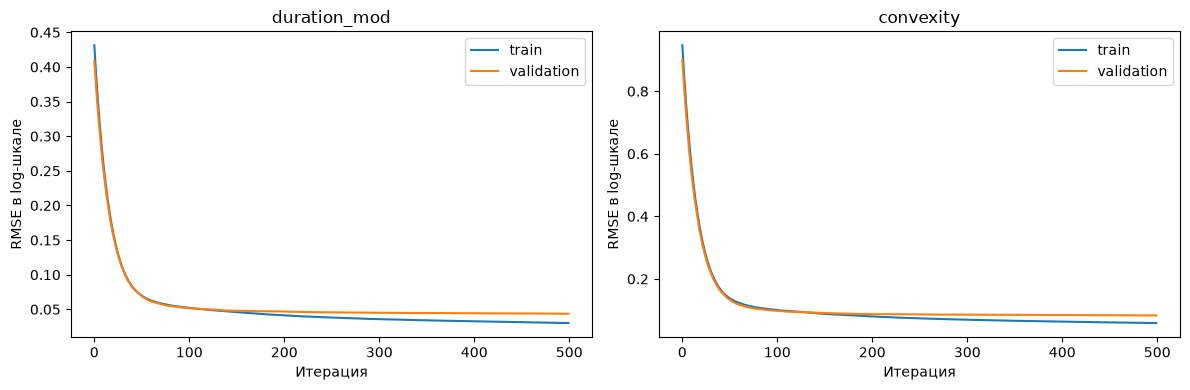

In [5]:
x_train = make_x(train)
drop_yield = np.random.default_rng(SEED).random(len(train)) < .2
x_train.loc[drop_yield, "ytm"] = np.nan
x_valid = make_x(valid)
models = {}
for target in TARGETS:
    print("Обучение", target)
    model = CatBoostRegressor(iterations=ITERATIONS, depth=6, learning_rate=.06, l2_leaf_reg=6,
        loss_function="RMSE", random_seed=SEED, thread_count=THREADS, allow_writing_files=False)
    model.fit(x_train, np.log1p(train[target].to_numpy()), cat_features=CATEGORICAL,
              eval_set=(x_valid, np.log1p(valid[target].to_numpy())), early_stopping_rounds=60, verbose=100)
    models[target] = model
    model.save_model(str(MODELS / f"{target}.cbm"))
    print("Деревьев:", model.tree_count_)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, target in zip(axes, TARGETS):
    history = models[target].get_evals_result()
    ax.plot(history["learn"]["RMSE"], label="train")
    ax.plot(history["validation"]["RMSE"], label="validation")
    ax.set(title=target, xlabel="Итерация", ylabel="RMSE в log-шкале")
    ax.legend()
plt.tight_layout()
plt.show()

## MAE и RMSE: более поздний период и новые эмитенты

,split,method,target,n,MAE,RMSE
0,test_time,median,duration_mod,86663,0.98030,1.28989
1,test_time,median,convexity,86663,5.32663,12.02060
2,test_time,group_median,duration_mod,86663,0.35026,0.51332
3,test_time,group_median,convexity,86663,1.92791,4.50784
4,test_time,catboost,duration_mod,86663,0.09103,0.14448
5,test_time,catboost,convexity,86663,0.40757,1.67564
6,test_time,catboost_without_yield,duration_mod,86663,0.11731,0.17325
7,test_time,catboost_without_yield,convexity,86663,0.58551,1.89808
8,test_unseen_issuers,median,duration_mod,27186,0.89289,1.07838
9,test_unseen_issuers,median,convexity,27186,4.18612,6.77078


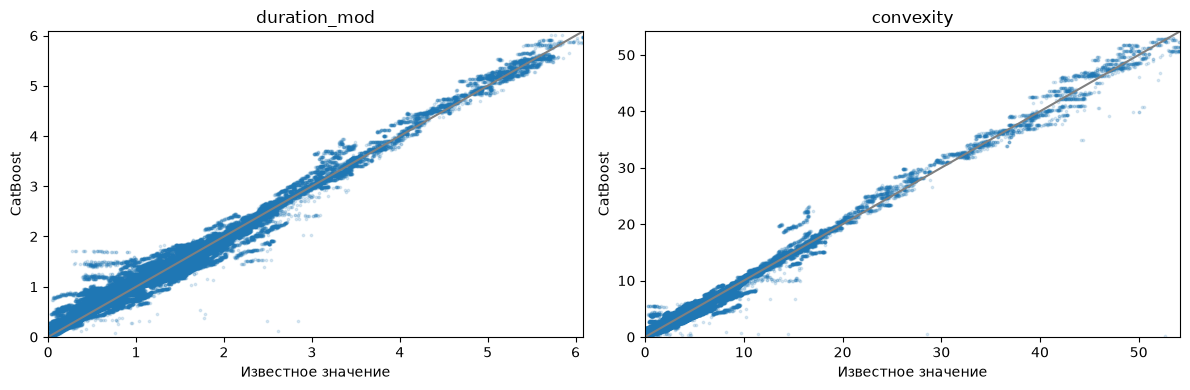

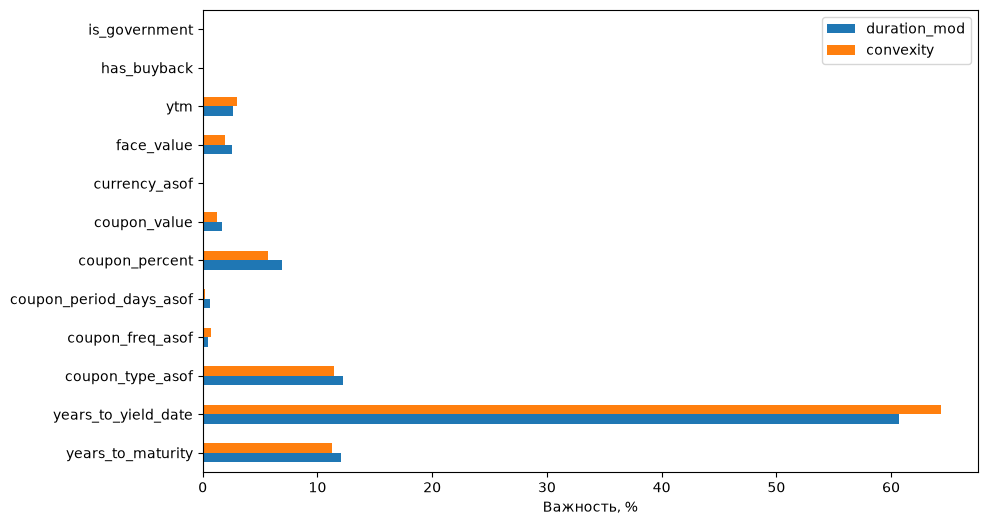

In [6]:
def model_predictions(frame, without_yield=False):
    x = make_x(frame, without_yield)
    return np.column_stack([np.maximum(np.expm1(models[target].predict(x)), 0) for target in TARGETS])

scores = []
predictions = {}
for split_name, frame in [("test_time", test_seen), ("test_unseen_issuers", test_unseen)]:
    variants = baseline_predictions(frame)
    variants["catboost"] = model_predictions(frame)
    variants["catboost_without_yield"] = model_predictions(frame, without_yield=True)
    predictions[split_name] = variants
    for method, values in variants.items():
        for j, target in enumerate(TARGETS):
            truth = frame[target].to_numpy()
            scores.append({"split": split_name, "method": method, "target": target, "n": len(frame),
                           "MAE": mean_absolute_error(truth, values[:, j]),
                           "RMSE": np.sqrt(mean_squared_error(truth, values[:, j]))})
metric_scores = pd.DataFrame(scores)
display(metric_scores.round(5))
metric_scores.to_csv(DATA / "catboost_metric_scores.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j, (ax, target) in enumerate(zip(axes, TARGETS)):
    ax.scatter(test_seen[target], predictions["test_time"]["catboost"][:, j], s=3, alpha=.15)
    top = max(test_seen[target].quantile(.99), 1)
    ax.plot([0, top], [0, top], color="gray")
    ax.set(title=target, xlabel="Известное значение", ylabel="CatBoost", xlim=(0, top), ylim=(0, top))
plt.tight_layout()
plt.show()
importance = pd.DataFrame({target: models[target].get_feature_importance() for target in TARGETS}, index=FEATURES)
importance.plot.barh(figsize=(10, 6))
plt.xlabel("Важность, %")
plt.show()

## Интервалы неопределённости

Отдельные MultiQuantile-модели предсказывают 10-й и 90-й процентили (номинально 80%).
Пересечения границ сортируем и показываем их долю. На отдельном calibration-периоде
расширяем интервал по ошибкам в log-шкале (split conformal/CQR).

Покрытие проверяем на окончательном test, включая новых эмитентов и отсутствие доходности.
80% - номинальный уровень, не гарантия при смене рынка или типа эмитента.
Документация: [CatBoost MultiQuantile](https://catboost.ai/docs/en/concepts/loss-functions-regression).

In [7]:
quantile_models = {}
calibration_radii = {}
interval_rows = []
interval_predictions = {}
for j, target in enumerate(TARGETS):
    print("Интервалы", target)
    qm = CatBoostRegressor(iterations=350, depth=6, learning_rate=.06, l2_leaf_reg=6,
        loss_function="MultiQuantile:alpha=0.1,0.5,0.9", random_seed=SEED,
        thread_count=THREADS, allow_writing_files=False)
    qm.fit(x_train, np.log1p(train[target].to_numpy()), cat_features=CATEGORICAL,
           eval_set=(x_valid, np.log1p(valid[target].to_numpy())), early_stopping_rounds=50, verbose=100)
    quantile_models[target] = qm
    qm.save_model(str(MODELS / f"{target}_quantiles.cbm"))
    for regime, no_yield in [("available_features", False), ("without_yield", True)]:
        cal_q = np.sort(qm.predict(make_x(calibration, no_yield)), axis=1)
        cal_y = np.log1p(calibration[target].to_numpy())
        nonconformity = np.maximum.reduce([cal_q[:, 0]-cal_y, cal_y-cal_q[:, 2], np.zeros(len(cal_y))])
        rank = min(len(cal_y), int(np.ceil((len(cal_y) + 1) * .8)))
        radius = float(np.partition(nonconformity, rank - 1)[rank - 1])
        calibration_radii[f"{target}:{regime}"] = radius
        for split_name, frame in [("test_time", test_seen), ("test_unseen_issuers", test_unseen)]:
            raw = qm.predict(make_x(frame, no_yield))
            crossings = ((raw[:, 0] > raw[:, 1]) | (raw[:, 1] > raw[:, 2])).mean()*100
            q = np.sort(raw, axis=1)
            low = np.maximum(np.expm1(q[:, 0]-radius), 0)
            high = np.maximum(np.expm1(q[:, 2]+radius), 0)
            interval_predictions[(split_name, target, regime)] = (low, high)
            truth = frame[target].to_numpy()
            raw_low, raw_high = np.maximum(np.expm1(q[:, 0]), 0), np.maximum(np.expm1(q[:, 2]), 0)
            interval_rows.append({"split": split_name, "target": target, "regime": regime, "n": len(frame),
                "raw_coverage_pct": np.mean((truth>=raw_low)&(truth<=raw_high))*100,
                "calibrated_coverage_pct": np.mean((truth>=low)&(truth<=high))*100,
                "median_width": np.median(high-low), "crossing_pct": crossings})
interval_scores = pd.DataFrame(interval_rows)
display(interval_scores.round(3))
interval_scores.to_csv(DATA / "catboost_interval_scores.csv", index=False)

Интервалы duration_mod
0:	learn: 0.1079202	test: 0.1012719	best: 0.1012719 (0)	total: 46.4ms	remaining: 16.2s


100:	learn: 0.0114232	test: 0.0114685	best: 0.0114685 (100)	total: 3.56s	remaining: 8.78s


200:	learn: 0.0092306	test: 0.0097810	best: 0.0097810 (200)	total: 6.98s	remaining: 5.17s


300:	learn: 0.0081355	test: 0.0092178	best: 0.0092117 (297)	total: 10.5s	remaining: 1.7s


349:	learn: 0.0077460	test: 0.0090366	best: 0.0090366 (349)	total: 12.1s	remaining: 0us

bestTest = 0.009036593152
bestIteration = 349



...

100:	learn: 0.0227503	test: 0.0218620	best: 0.0218620 (100)	total: 3.35s	remaining: 8.25s


200:	learn: 0.0179113	test: 0.0178809	best: 0.0178743 (199)	total: 6.7s	remaining: 4.96s


300:	learn: 0.0156553	test: 0.0165721	best: 0.0165710 (298)	total: 10.1s	remaining: 1.65s


349:	learn: 0.0149213	test: 0.0162898	best: 0.0162898 (349)	total: 11.8s	remaining: 0us

bestTest = 0.01628983198
bestIteration = 349



,split,target,regime,n,raw_coverage_pct,calibrated_coverage_pct,median_width,crossing_pct
0,test_time,duration_mod,available_features,86663,50.515,73.982,0.153,16.240
1,test_unseen_issuers,duration_mod,available_features,27186,52.682,78.603,0.149,17.402
2,test_time,duration_mod,without_yield,86663,52.021,72.243,0.253,1.915
3,test_unseen_issuers,duration_mod,without_yield,27186,51.920,72.935,0.248,2.810
4,test_time,convexity,available_features,86663,55.005,75.434,0.544,13.452
5,test_unseen_issuers,convexity,available_features,27186,59.299,80.836,0.498,10.649
6,test_time,convexity,without_yield,86663,58.252,73.096,0.912,5.516
7,test_unseen_issuers,convexity,without_yield,27186,59.939,76.322,0.880,4.576


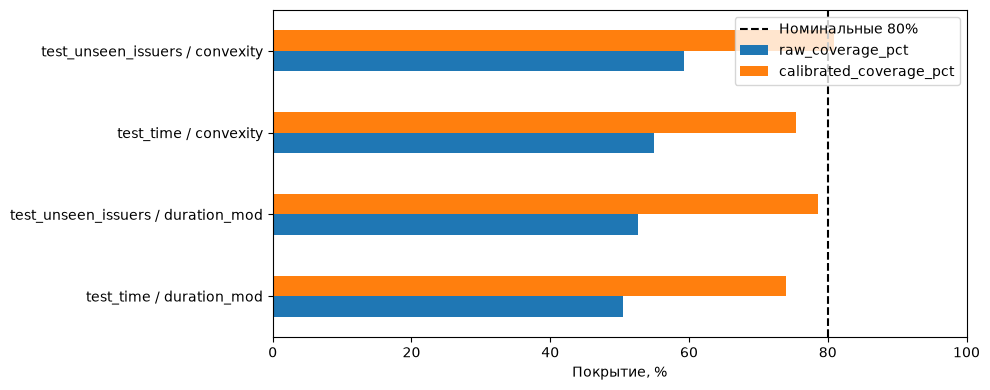

In [8]:
coverage_plot = interval_scores[interval_scores["regime"].eq("available_features")].copy()
coverage_plot["label"] = coverage_plot["split"] + " / " + coverage_plot["target"]
ax = coverage_plot.set_index("label")[["raw_coverage_pct", "calibrated_coverage_pct"]].plot.barh(figsize=(10, 4))
ax.axvline(80, color="black", linestyle="--", label="Номинальные 80%")
ax.set(xlabel="Покрытие, %", xlim=(0, 100), ylabel="")
ax.legend()
plt.tight_layout()
plt.show()

## Ошибка оценки риска

Для сдвига доходности +1 б.п. используем формулу проекта:
`DV01 = FairValue * (-DurationMod * 0.0001 + 0.5 * Convexity * 1e-8)`.
Знак соответствует изменению стоимости: для покупки он отрицательный.

Стоимость позиции нормируем до 1 млн рублей для сравнения разных бумаг.
Показываем ошибки дюрации, выпуклости и их совместный вклад.

In [9]:
def dv01(fair_value, duration, convexity):
    return fair_value * (-np.asarray(duration)*1e-4 + .5*np.asarray(convexity)*1e-8)

risk_rows = []
for split_name, frame in [("test_time", test_seen), ("test_unseen_issuers", test_unseen)]:
    true_d, true_c = frame["duration_mod"].to_numpy(), frame["convexity"].to_numpy()
    reference = dv01(1_000_000, true_d, true_c)
    for method, values in predictions[split_name].items():
        for mode, d, c in [("duration_only", values[:, 0], true_c), ("convexity_only", true_d, values[:, 1]),
                           ("both", values[:, 0], values[:, 1])]:
            error = dv01(1_000_000, d, c)-reference
            risk_rows.append({"split": split_name, "method": method, "error_source": mode,
                              "MAE_rub_per_million": np.mean(np.abs(error)),
                              "RMSE_rub_per_million": np.sqrt(np.mean(error**2)),
                              "p95_abs_error_rub": np.quantile(np.abs(error), .95)})
risk_scores = pd.DataFrame(risk_rows)
display(risk_scores.round(5))
risk_scores.to_csv(DATA / "catboost_dv01_scores.csv", index=False)


,split,method,error_source,MAE_rub_per_million,RMSE_rub_per_million,p95_abs_error_rub
0,test_time,median,duration_only,98.03021,128.98851,183.83643
1,test_time,median,convexity_only,0.02663,0.06010,0.06188
2,test_time,median,both,98.00361,128.93818,183.80295
3,test_time,group_median,duration_only,35.02641,51.33199,90.67697
4,test_time,group_median,convexity_only,0.00964,0.02254,0.03003
5,test_time,group_median,both,35.01683,51.31379,90.65009
6,test_time,catboost,duration_only,9.10301,14.44809,30.71574
7,test_time,catboost,convexity_only,0.00204,0.00838,0.00677
8,test_time,catboost,both,9.10113,14.44416,30.70353
9,test_time,catboost_without_yield,duration_only,11.73107,17.32478,34.82073


## Заполнение пропусков

Отбираем поддерживаемые облигации с недостающими метриками.
Известные значения сохраняем. Для прогнозов записываем источник, интервал
и отметку о необходимости проверки. Результат выгружаем отдельно от исходных данных.

In [10]:
details_snapshot = pd.read_parquet(DATA / "bonds.parquet").set_index("SECID")["COUPON_DETAILS"]
known_coupon_terms = ~all_data["SECID"].map(details_snapshot).fillna("").str.contains("неизвестными", case=False)
supported = (known_coupon_terms & all_data["coupon_type"].isin(["fixed", "zero"]) & ~all_data["is_structured"]
    & all_data["trade_date"].ge(calibration_end)
    & all_data["settlement_calendar_exact"] & all_data["calc_status"].isin(["ok", "missing_yield"])
    & ~all_data["validation_status"].eq("mismatch")
    & all_data["years_to_yield_date"].between(train["years_to_yield_date"].min(), train["years_to_yield_date"].max())
    & all_data["currency_asof"].isin(train["currency_asof"].unique())
    & ~all_data["SECID"].str.startswith("SU52"))
candidates = all_data[supported & all_data[TARGETS].isna().any(axis=1)].copy()
candidates["review_required"] = True
print("Строк-кандидатов с реальными пропусками:", len(candidates))
if len(candidates):
    point_values = model_predictions(candidates)
    for j, target in enumerate(TARGETS):
        missing = candidates[target].isna()
        candidates[f"{target}_filled"] = candidates[target].where(~missing, point_values[:, j])
        candidates[f"{target}_is_imputed"] = missing
        candidates[f"{target}_source"] = np.where(missing, "catboost_candidate", "known")
        raw_q = np.sort(quantile_models[target].predict(make_x(candidates)), axis=1)
        regime = np.where(candidates["ytm"].notna(), "available_features", "without_yield")
        radii = np.array([calibration_radii[f"{target}:{r}"] for r in regime])
        candidates[f"{target}_low"] = np.where(missing, np.maximum(np.expm1(raw_q[:, 0]-radii), 0), np.nan)
        candidates[f"{target}_high"] = np.where(missing, np.maximum(np.expm1(raw_q[:, 2]+radii), 0), np.nan)
        assert candidates.loc[~missing, f"{target}_filled"].equals(candidates.loc[~missing, target])
    display(candidates[["SECID", "trade_date", "duration_mod", "duration_mod_filled", "duration_mod_source",
                        "convexity", "convexity_filled", "convexity_source"]].head(15))
candidates.to_parquet(DATA / "metric_imputation_candidates.parquet", index=False)

Строк-кандидатов с реальными пропусками: 9387


,SECID,trade_date,duration_mod,duration_mod_filled,duration_mod_source,convexity,convexity_filled,convexity_source
53943,BYM000001818,2026-04-02,NaN,1.100067,catboost_candidate,NaN,2.257287,catboost_candidate
53944,BYM000001818,2026-04-03,NaN,1.096615,catboost_candidate,NaN,2.249036,catboost_candidate
53945,BYM000001818,2026-04-06,NaN,1.093331,catboost_candidate,NaN,2.209028,catboost_candidate
53946,BYM000001818,2026-04-07,NaN,1.096850,catboost_candidate,NaN,2.235464,catboost_candidate
53947,BYM000001818,2026-04-08,NaN,1.096615,catboost_candidate,NaN,2.249036,catboost_candidate
53948,BYM000001818,2026-04-09,NaN,1.097129,catboost_candidate,NaN,2.239294,catboost_candidate
53949,BYM000001818,2026-04-10,NaN,1.093331,catboost_candidate,NaN,2.209028,catboost_candidate
53950,BYM000001818,2026-04-13,NaN,1.093331,catboost_candidate,NaN,2.209028,catboost_candidate
53951,BYM000001818,2026-04-14,NaN,1.093331,catboost_candidate,NaN,2.209028,catboost_candidate
53952,BYM000001818,2026-04-15,NaN,1.095432,catboost_candidate,NaN,2.193939,catboost_candidate


In [11]:
assert hashlib.sha256((DATA / "market_data.parquet").read_bytes()).hexdigest() == market_hash_before
print("Исходный market_data.parquet не изменён; известные значения сохранены")

Исходный market_data.parquet не изменён; известные значения сохранены


In [12]:
test_exports = []
for split_name, frame in [("test_time", test_seen), ("test_unseen_issuers", test_unseen)]:
    result = frame[["SECID", "trade_date", "issuer_id", "currency_asof", "duration_mod", "convexity"]].copy()
    result["split"] = split_name
    for method, values in predictions[split_name].items():
        for j, target in enumerate(TARGETS):
            result[f"{target}_{method}"] = values[:, j]
    for target in TARGETS:
        low, high = interval_predictions[(split_name, target, "available_features")]
        result[f"{target}_low"] = low
        result[f"{target}_high"] = high
    test_exports.append(result)
test_predictions = pd.concat(test_exports, ignore_index=True)
test_predictions.to_parquet(DATA / "catboost_test_predictions.parquet", index=False)
print("Сохранены ответы и предсказания для независимой проверки:", len(test_predictions), "строк")
display(test_predictions.head())

Сохранены ответы и предсказания для независимой проверки: 113849 строк


,SECID,trade_date,issuer_id,currency_asof,duration_mod,convexity,split,duration_mod_median,convexity_median,duration_mod_group_median,convexity_group_median,duration_mod_catboost,convexity_catboost,duration_mod_catboost_without_yield,convexity_catboost_without_yield,duration_mod_low,duration_mod_high,convexity_low,convexity_high
0,BYM000002154,2026-04-01,4452,USD,1.114526,2.329391,test_time,1.847801,5.597649,1.864760,5.326883,1.100067,2.263878,1.027963,2.017234,1.063780,1.183550,2.053034,2.460028
1,BYM000002469,2026-04-01,4452,USD,3.318687,14.899559,test_time,1.847801,5.597649,3.262788,14.258890,2.992407,12.916939,2.927798,12.049833,3.049691,3.324694,12.683275,14.978709
2,RU000A0JS4Z7,2026-04-01,406,RUB,1.127240,2.336020,test_time,1.847801,5.597649,1.547912,3.952937,1.083517,2.170765,1.017199,1.978416,1.045046,1.213819,1.985686,2.470599
3,RU000A0JSGV0,2026-04-01,712,RUB,0.226269,0.243146,test_time,1.847801,5.597649,0.213746,0.231793,0.217628,0.194935,0.214702,0.216930,0.183267,0.234159,0.186389,0.257547
4,RU000A0JSQ58,2026-04-01,710,RUB,0.280242,0.320137,test_time,1.847801,5.597649,0.213746,0.231793,0.262256,0.285067,0.232129,0.229831,0.254645,0.305583,0.265285,0.375931


## Сохранение настроек модели

In [13]:
metadata = {"features": FEATURES, "categorical": CATEGORICAL, "target_transform": "log1p",
            "train_end_exclusive": str(train_end.date()), "validation_end_exclusive": str(valid_end.date()),
            "calibration_end_exclusive": str(calibration_end.date()), "unseen_issuers": sorted(unseen_issuers),
            "calibration_radii_log": calibration_radii, "seed": SEED}
metadata["model_files"] = {target: f"{target}.cbm" for target in TARGETS}
metadata["interval_model_files"] = {target: f"{target}_quantiles.cbm" for target in TARGETS}
(MODELS / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
print("Модели, метрики, ошибки DV01 и кандидаты заполнения сохранены в data/")

Модели, метрики, ошибки DV01 и кандидаты заполнения сохранены в data/


## Вывод

При известной текущей доходности модель заметно лучше простых медианных оценок.
На поздних датах MAE дюрации составляет 0,0910 года против 0,3503 у групповой медианы,
а MAE выпуклости - 0,4076 лет² против 1,9279. Снижение ошибки составляет примерно
74% и 79%. На новых эмитентах MAE равна 0,0905 года и 0,3682 лет² соответственно.
Это показывает, что модель использует общие характеристики облигаций, а не только
повторяет ответы знакомых выпусков.

Без текущей доходности ошибки возрастают: на поздних датах MAE достигает 0,1173 года
для дюрации и 0,5855 лет² для выпуклости. Доходность полезна для восстановления,
но её отсутствие не делает расчёт невозможным. При этом обучение проводилось
на отобранных качественных наблюдениях: проверка не доказывает такую же точность
для любых реальных пропусков.

RMSE выпуклости на поздних датах равна 1,6756 при MAE 0,4076. Такой разрыв указывает
на редкие крупные ошибки. Поэтому оценивать качество только по средней абсолютной
ошибке недостаточно. Для позиции стоимостью 1 млн рублей MAE изменения стоимости
при сдвиге доходности на 1 б.п. составляет 9,10 рубля, а 95-й перцентиль абсолютной
ошибки - 30,70 рубля. На этом малом сдвиге основной вклад в ошибку даёт дюрация.

Калибровка не обеспечила заявленное покрытие интервалов на позднем периоде:
получено 74,0% для дюрации и 75,4% для выпуклости вместо 80%. Для новых эмитентов
покрытие составляет 78,6% и 80,8%. Эти интервалы пока нельзя считать надёжной
гарантией точности при изменении рыночных условий.

Для применения в сервисе нужно сохранять известные значения и заполнять только
недостающие. Модель проверена на обычных облигациях с известными условиями выплат;
флоатеры, структурные бумаги и неполный календарь 2022 года исключены из обучения.
Выпуклость рассчитана по графику выплат, поэтому её точность требует дополнительной
независимой проверки. Для реальных пропусков нужны отдельная проверка качества
и согласованная допустимая ошибка оценки риска.

## Подключение к БД

Модель можно использовать в сервисе. По идентификатору облигации сервис читает
из БД характеристики на дату оценки и формирует те же признаки, что при обучении.
Два файла CatBoost и metadata.json загружаются один раз при запуске сервиса.
Для интервалов дополнительно загружаются две квантильные модели;
коэффициенты калибровки сохранены в metadata.json.
Известные метрики сохраняются, недостающие получают отдельную отметку источника.

Для оценки возможной сделки дополнительно нужны цена, НКД, номинал, количество
и направление покупки или продажи. По ним рассчитываются стоимость позиции
и её чувствительность к изменению доходности. До вызова модели необходимо
проверить свежесть данных и принадлежность бумаги к поддерживаемой выборке.
Денежные величины должны быть в одной валюте; для рублёвой оценки валютной
позиции дополнительно нужен курс пересчёта.

Сейчас модель оценивает недостающие метрики и риск, но не определяет выгодность
сделки. Для рекомендации понадобятся отдельные правила по доходности, ликвидности,
комиссиям и ограничениям портфеля. Для реализации подключения нужны схема БД
и согласованный формат результата. Подключение к реальной БД пока не реализовано.